# Truncation order and path length
Run all cells to export the panels in figures/. The bundled matrices are the error and rank values printed by the original Truncation notebook, including its NaN masks.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator, FormatStrFormatter

OUT = Path("figures")
OUT.mkdir(exist_ok=True)
with np.load("data/truncation.npz") as archive:
    data = dict(archive)

def plot_case(case, metrics):
    for metric in metrics:
        error, rank = data[f"{case}__{metric}"]
        order = np.arange(1, len(error) + 1)
        fig, left = plt.subplots(figsize=(3, 2))
        right = left.twinx()
        for j, color in enumerate(("b", "g", "r")):
            left.plot(order, error[:, j], "o-", color=color, linewidth=2, alpha=.7)
            right.plot(order, rank[:, j], "s--", color=color, linewidth=2, alpha=.7)
        for axis, fmt in ((left, "%.2f"), (right, "%.4f")):
            axis.spines["top"].set_visible(False)
            axis.yaxis.set_major_formatter(FormatStrFormatter(fmt))
            axis.yaxis.set_major_locator(MaxNLocator(nbins=3))
            axis.tick_params(labelsize=12)
        left.xaxis.set_major_locator(MaxNLocator(integer=True))
        if metric not in ("Peak Response", "Amplification"):
            left.set_ylim(0, 1.1 * np.nanmax(error))
        elif case == "cross_ii_m":
            left.set_ylim(.8, 1.06)
            right.set_ylim(.99895, 1.0001)
        fig.tight_layout()
        fig.savefig(OUT / f"{case}_{metric}.pdf", dpi=300)
        plt.show()
        plt.close(fig)

## constant heter

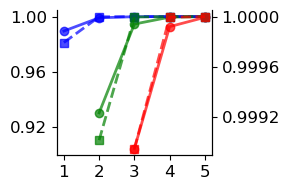

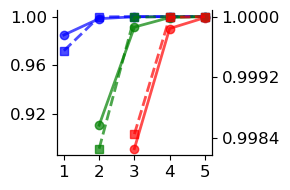

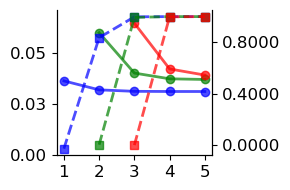

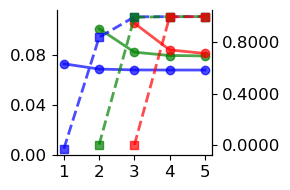

In [2]:
plot_case("constant_heter", ['Peak Response', 'Amplification', 'Time Constant', 'Relative Time'])

## pulse heter

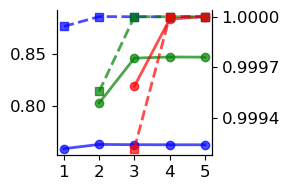

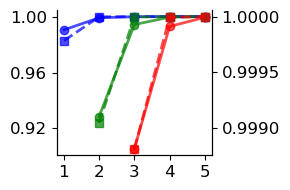

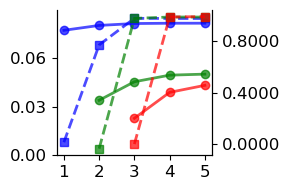

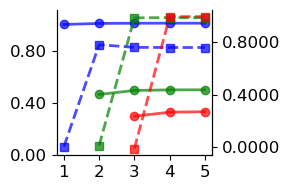

In [3]:
plot_case("pulse_heter", ['Peak Response', 'Amplification', 'Time Constant', 'Peak Time'])

## square heter

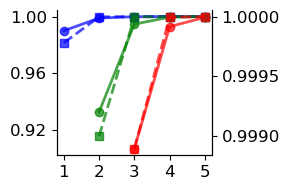

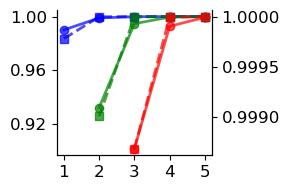

In [4]:
plot_case("square_heter", ['Peak Response', 'Amplification'])

## cross im m

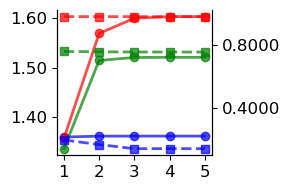

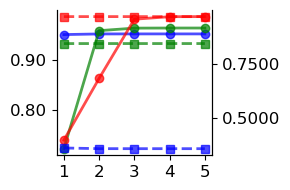

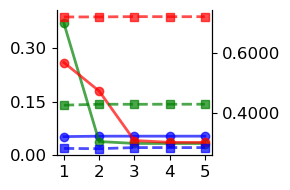

In [5]:
plot_case("cross_im_m", ['Peak Response', 'Amplification', 'Peak Time'])

## cross im m second

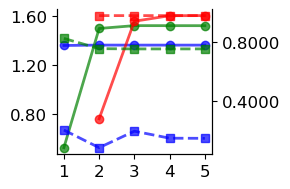

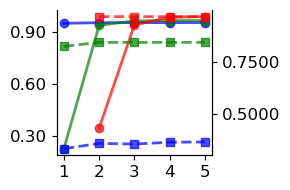

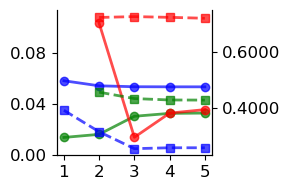

In [6]:
plot_case("cross_im_m_second", ['Peak Response', 'Amplification', 'Peak Time'])

## cross im m heter

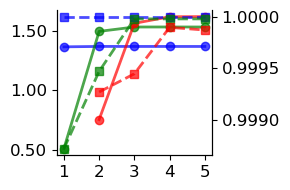

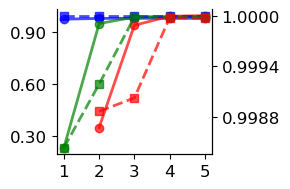

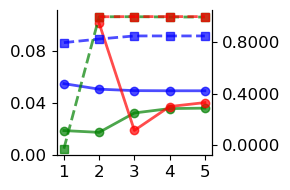

In [7]:
plot_case("cross_im_m_heter", ['Peak Response', 'Amplification', 'Peak Time'])

## cross ii m

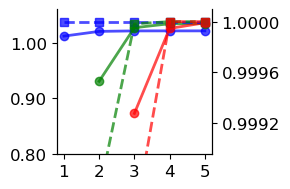

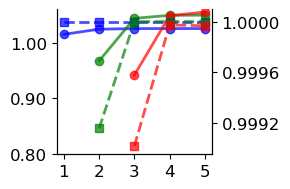

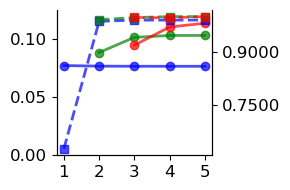

In [8]:
plot_case("cross_ii_m", ['Peak Response', 'Amplification', 'Time Constant'])

## cross ij m 1

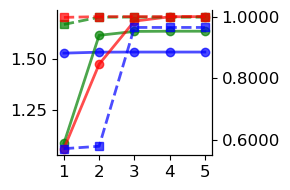

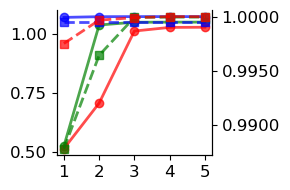

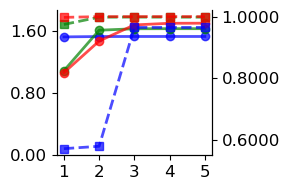

In [9]:
plot_case("cross_ij_m_1", ['Peak Response', 'Amplification', 'Peak Time'])

## cross ij m 2

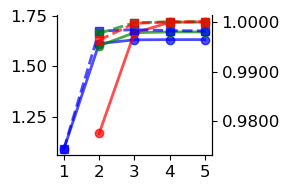

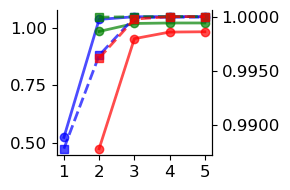

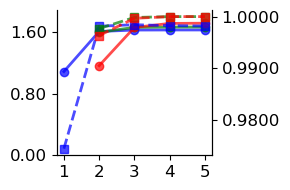

In [10]:
plot_case("cross_ij_m_2", ['Peak Response', 'Amplification', 'Peak Time'])

## cross ij m 3

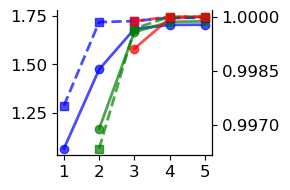

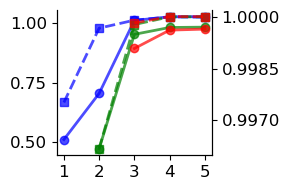

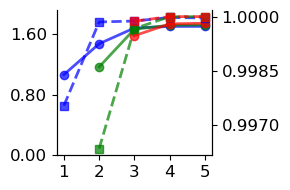

In [11]:
plot_case("cross_ij_m_3", ['Peak Response', 'Amplification', 'Peak Time'])

## Path-length legend

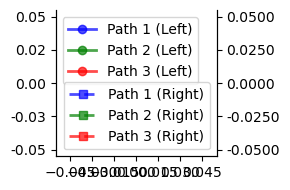

In [12]:
colors = ["b","g","r"]
path_max = 3
x_values = np.arange(1,6)
fig, ax = plt.subplots(figsize=(3, 2))
ax2 = ax.twinx()

for path_length in range(path_max):
        ax.plot(x_values, [np.nan for _ in range(len(x_values))], marker='o', linestyle='-', linewidth=2, 
                color=colors[path_length % len(colors)], alpha=0.7, label=f'Path {path_length+1} (Left)')
        ax2.plot(x_values, [np.nan for _ in range(len(x_values))], marker='s', linestyle='--', linewidth=2, 
                color=colors[path_length % len(colors)], alpha=0.7, label=f'Path {path_length+1} (Right)')

ax.spines['top'].set_visible(False)
ax2.spines['top'].set_visible(False)

ax.xaxis.set_major_locator(MaxNLocator(integer=True))  # Forces integer ticks (1,2,3,4,5)

ax.yaxis.set_major_formatter(FormatStrFormatter('%.2f'))  # Decimal Number
ax2.yaxis.set_major_formatter(FormatStrFormatter('%.4f'))  # Decimal Number

plt.tight_layout()
ax.legend(loc = 'upper left')
ax2.legend(loc = 'lower right')
plt.savefig(OUT / "label.pdf", dpi=300)
plt.show()
plt.close(fig)